In [1]:
%load_ext byname

In [2]:
from notebook_cache import NotebookCache

# results and prints live on disk, so they survive kernel restarts; one folder per notebook
cache = NotebookCache('../cache/uva')

# UVA, simplest form, built forward (byname + cache)

One transformer reads the past frames, fills in the future frames _and_ the next actions; at run time only the action half is used. Same data, split and eval seeds as `act_byname.ipynb`.

### step 0 — the data, as in ACT


In [3]:
from pathlib import Path

import numpy as np
from lerobot.datasets.lerobot_dataset import LeRobotDataset
from numpy.typing import NDArray

np.set_printoptions(precision=3, suppress=True)
REPO = Path.cwd().parent

In [4]:
@cache
def load_table():
    # straight from the table, no video decode
    ds = LeRobotDataset('dream_robot/pick_place_cube', root=REPO / 'data/robosuite/pick_place_cube')
    return (
        state=np.asarray(ds.hf_dataset['observation.state'], dtype=np.float32),  # [N, 8]
        action=np.asarray(ds.hf_dataset['action'], dtype=np.float32),  # [N, 8]
        episode=np.asarray(ds.hf_dataset['episode_index'], dtype=np.int64),  # [N], which demo
    )

load_table: cached, 1 call(s) stored


In [5]:
(state=, action=, episode=) = load_table()
val_eps = np.random.default_rng(0).permutation(25)[:5]  # same 5 held-out demos as act_byname
is_val = np.isin(episode, val_eps)  # [N]
print(f'{state.shape=}  {action.shape=}  {val_eps=}  train {(~is_val).sum()}  val {is_val.sum()}')

state.shape=(5288, 8)  action.shape=(5288, 8)  val_eps=array([19,  4, 10, 11, 24])  train 4218  val 1070


### step 1 — the target grows: next 16 actions _and_ the frames 4, 8, 12, 16 steps ahead


In [6]:
def rows_at(episode: NDArray[np.int64], offsets: list[int] | range) -> NDArray[np.int64]:
    # [N, len(offsets)]: the row of step t + o for every row t, clipped to t's own demo
    first = np.searchsorted(episode, episode, side='left')  # [N]
    last = np.searchsorted(episode, episode, side='right') - 1  # [N]
    idx = np.arange(len(episode))[:, None] + np.asarray(offsets)
    return np.clip(idx, first[:, None], last[:, None]).astype(np.int64)


past = rows_at(episode, [-12, -8, -4, 0])  # what it sees: 4 frames, now and 4, 8, 12 back
future = rows_at(episode, [4, 8, 12, 16])  # what it imagines: 4 frames ahead
chunk = rows_at(episode, range(16))  # what it does: the next 16 actions
t = int(np.flatnonzero(episode == 2)[60])  # demo 2, step 60, as in act_byname
print(f'{past.shape=} {future.shape=} {chunk.shape=}\nrow {t}: past {past[t]}  future {future[t]}')

past.shape=(5288, 4) future.shape=(5288, 4) chunk.shape=(5288, 16)
row 491: past [479 483 487 491]  future [495 499 503 507]


### step 2 — both cameras into RAM (~20 s the first time, cached after), and what row 491 sees vs must imagine


In [7]:
import matplotlib.pyplot as plt
import torch
from torch import Tensor

In [8]:
@cache
def load_images():
    # every frame decoded from both videos once, kept as uint8 (~0.5 GB), as act_byname step 3
    ds = LeRobotDataset('dream_robot/pick_place_cube', root=REPO / 'data/robosuite/pick_place_cube')
    top = np.zeros((len(ds), 3, 128, 128), dtype=np.uint8)  # [N, 3, H, W]
    wrist = np.zeros_like(top)
    for i in range(len(ds)):
        item: dict[str, Tensor] = ds[i]  # this frame, decoded from both videos
        top[i] = (item['observation.images.top'] * 255).round().to(torch.uint8).numpy()
        wrist[i] = (item['observation.images.wrist'] * 255).round().to(torch.uint8).numpy()
    return (top=, wrist=)

load_images: cached, 1 call(s) stored


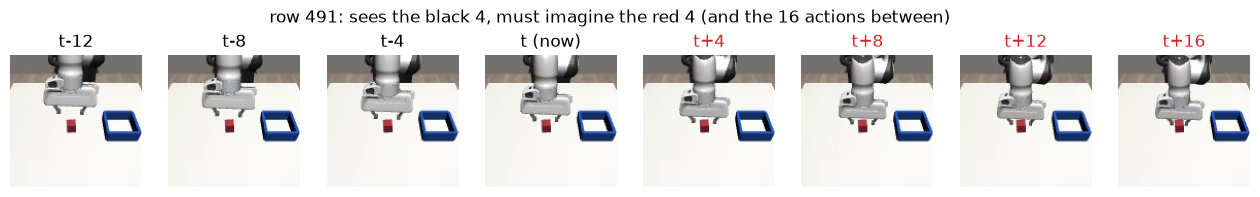

In [9]:
(top=, wrist=) = load_images()
rows = list(map(int, np.concatenate([past[t], future[t]])))  # 4 seen, 4 to imagine
names = ['t-12', 't-8', 't-4', 't (now)', 't+4', 't+8', 't+12', 't+16']
fig = plt.figure(figsize=(16, 2.3))
for i, (row, name) in enumerate(zip(rows, names)):
    ax = fig.add_subplot(1, 8, i + 1)
    ax.imshow(np.transpose(top[row], (1, 2, 0)))
    ax.set_title(name, color='tab:red' if '+' in name else 'k')
    ax.axis('off')
fig.suptitle(f'row {t}: sees the black 4, must imagine the red 4 (and the 16 actions between)')
plt.show()

### step 3 — a frame becomes a grid of tokens, not one vector

Our stand-in for UVA's frozen VAE (which gives a 16×16 grid): 4 stride-2 convs, 128 px → 8×8, one 128-d token per 16×16 px patch.


In [10]:
from torch import nn

device = 'cuda'
GRID, D = 8, 128  # 8 x 8 tokens per frame, each a D-dim vector


class Patches(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(3, 32, 4, 2, 1),
            nn.GELU(),  # -> [B, 32, 64, 64]
            nn.Conv2d(32, 64, 4, 2, 1),
            nn.GELU(),  # -> [B, 64, 32, 32]
            nn.Conv2d(64, 128, 4, 2, 1),
            nn.GELU(),  # -> [B, 128, 16, 16]
            nn.Conv2d(128, D, 4, 2, 1),  # -> [B, D, 8, 8]
        )

    def forward(self, x: Tensor) -> Tensor:
        # x: [B, 3, 128, 128] floats in [0, 1]
        # out: [B, 64, D], one token per patch, row by row
        grid: Tensor = self.conv(x)  # [B, D, 8, 8]
        return grid.flatten(2).transpose(1, 2)

tokens: (4, 64, 128)  (4 frames x 64 patches x D)


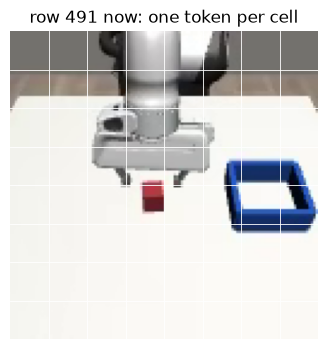

In [11]:
frames = (
    torch.tensor(top[past[t]]).to(device).float() / 255
)  # row t's 4 seen frames, [4, 3, 128, 128]
tokens: Tensor = Patches().to(device)(frames)  # untrained: only the shape means anything yet
print(f'tokens: {tuple(tokens.shape)}  (4 frames x 64 patches x D)')
fig = plt.figure(figsize=(4, 4))
ax = fig.add_subplot()
ax.imshow(np.transpose(top[t], (1, 2, 0)))
for k in range(1, GRID):  # patch borders, every 16 px
    ax.axhline(k * 16 - 0.5, color='w', lw=0.6)
    ax.axvline(k * 16 - 0.5, color='w', lw=0.6)
ax.set_title(f'row {t} now: one token per cell')
ax.axis('off')
plt.show()

### step 4 — a seen token = what's in its patch + **when** + **where**


In [12]:
# the pieces the model will own, built loose here to see the shapes (as act_byname step 17)
when = nn.Embedding(12 + 16 + 1, D).to(device)  # learned, one row per step offset -12 .. +16
where = nn.Embedding(GRID * GRID, D).to(device)  # learned, one row per patch
past_t = torch.tensor([-12, -8, -4, 0], device=) + 12  # offsets -> rows of `when`

grids: Tensor = Patches().to(device)(frames)  # [4, 64, D], what is in each patch (step 3)
frame_when: Tensor = when(past_t)[:, None]  # [4, 1, D], one per frame, same for its 64 patches
seen_tok = grids + frame_when + where.weight  # [4, 64, D]: + which frame + which patch
print(
    tuple(grids.shape),
    '+',
    tuple(frame_when.shape),
    '+',
    tuple(where.weight.shape),
    '->',
    tuple(seen_tok.shape),
)

(4, 64, 128) + (4, 1, 128) + (64, 128) -> (4, 64, 128)


### step 5 — a future slot = one learned **unknown** + when + where

Every future slot starts as the same vector; only its when and where differ. It is a question: _what is at this patch at this step?_


In [13]:
unknown = nn.Parameter(torch.zeros(D, device=))  # learned, shared by every future slot
future_t = torch.tensor([4, 8, 12, 16], device=) + 12
future_tok: Tensor = unknown + when(future_t)[:, None] + where.weight  # [4, 64, D]
print(tuple(future_tok.shape), '= 4 future frames x 64 patches, nothing seen in them')

(4, 64, 128) = 4 future frames x 64 patches, nothing seen in them


### step 6 — the action slots, and the joints as one token


In [14]:
act = nn.Parameter(torch.zeros(D, device=))  # learned, shared by every action slot
act_tok: Tensor = act + when(torch.arange(16, device=) + 12)  # [16, D]: steps t .. t+15
joints_in = nn.Linear(8, D).to(device)  # the arm's 8 readings -> one D-wide token
now_tok: Tensor = joints_in(torch.tensor(state[t], device=)) + when.weight[12]  # [D], at t
print(tuple(act_tok.shape), tuple(now_tok.shape))

(16, 128) (128,)


### step 7 — one sequence; a **role** tag says which kind each token is


In [15]:
role = nn.Embedding(4, D).to(device)  # learned: seen, future, action, joints
parts = [
    seen_tok.flatten(0, 1) + role.weight[0],  # [256, D]
    future_tok.flatten(0, 1) + role.weight[1],  # [256, D]
    act_tok + role.weight[2],  # [16, D]
    (now_tok + role.weight[3])[None],  # [1, D]
]
seq = torch.cat(parts)  # [529, D]
print([tuple(x.shape) for x in parts], '->', tuple(seq.shape))

[(256, 128), (256, 128), (16, 128), (1, 128)] -> (529, 128)


### step 8 — the transformer: every token reads every other

After it, the future slots and action slots hold answers; the heads in the next steps read them out.


In [16]:
layer = nn.TransformerEncoderLayer(D, 4, 4 * D, 0.0, 'gelu', batch_first=True, norm_first=True)
body = nn.TransformerEncoder(layer, 4, enable_nested_tensor=False).to(device)  # 4 layers, 4 heads
out: Tensor = body(seq[None])  # [1, 529, D]
print(f'{tuple(out.shape)}: future answers out[:, 256:512], action answers out[:, 512:528]')

(1, 529, 128): future answers out[:, 256:512], action answers out[:, 512:528]


### step 9 — the same, packed into `Board` (what training uses)

Steps 4–8 in one module, batched. `future_steps` is the knob: how many frames ahead it imagines.


In [17]:
class Board(nn.Module):
    def __init__(self, future_steps: list[int], layers: int = 4):
        super().__init__()
        self.past_t = torch.tensor([-12, -8, -4, 0]) + 12  # step offsets -> rows of `when`
        self.future_t = torch.tensor(future_steps) + 12
        self.patches = Patches()
        self.joints = nn.Linear(8, D)
        self.unknown = nn.Parameter(torch.zeros(D))  # every future slot starts as this
        self.act = nn.Parameter(torch.zeros(D))  # every action slot starts as this
        self.when = nn.Embedding(12 + 16 + 1, D)  # step offset -12 .. +16
        self.where = nn.Embedding(GRID * GRID, D)  # which patch
        self.role = nn.Embedding(4, D)  # past, future, action, joints
        layer = nn.TransformerEncoderLayer(
            D, 4, 4 * D, 0.0, 'gelu', batch_first=True, norm_first=True
        )
        self.body = nn.TransformerEncoder(layer, layers, enable_nested_tensor=False)

    def forward(self, past: Tensor, joints: Tensor) -> Tensor:
        # past: [B, 4, 3, 128, 128] in [0, 1];  joints: [B, 8] radians, now
        # out: [B, 4*64 + F*64 + 16 + 1, D], every token after reading the whole board
        B, dv = past.shape[0], past.device
        where, role = self.where.weight, self.role.weight  # [64, D], [4, D]
        grids: Tensor = self.patches(past.flatten(0, 1))  # [B*4, 64, D]
        seen: Tensor = grids.unflatten(0, (B, 4))  # [B, 4, 64, D]
        seen = seen + self.when(self.past_t.to(dv))[:, None] + where + role[0]
        future: Tensor = (
            self.unknown + self.when(self.future_t.to(dv))[:, None] + where + role[1]
        )  # [F, 64, D]
        act: Tensor = self.act + self.when(torch.arange(16, device=dv) + 12) + role[2]  # [16, D]
        now: Tensor = self.joints(joints) + self.when.weight[12] + role[3]  # [B, D]
        x = torch.cat(
            [
                seen.flatten(1, 2),
                future.flatten(0, 1).expand(B, -1, -1),
                act.expand(B, -1, -1),
                now[:, None],
            ],
            dim=1,
        )
        out: Tensor = self.body(x)
        return out

In [18]:
board = Board(future_steps=[4, 8, 12, 16]).to(device)
seen = torch.tensor(top[past[t]]).to(device).float()[None] / 255  # [1, 4, 3, 128, 128]
out: Tensor = board(seen, torch.tensor(state[t]).to(device)[None])
n = sum(p.numel() for p in board.parameters())
print(
    f'board {tuple(out.shape)} = 256 seen + 256 future + 16 action + 1 joints tokens;  {n / 1e6:.2f}M params'
)

board (1, 529, 128) = 256 seen + 256 future + 16 action + 1 joints tokens;  1.23M params
